# Crypto Treasury Risk Monitor — V1

Sofia Dawn Estrada

Historical BTC/ETH market-risk analysis using real Yahoo Finance daily prices (2024–2025), hypothetical $10,000 holdings initially split 70/30, and example review limits. Snapshot: December 31, 2025. Manually run notebook; no live feed or scheduled alerts.

Install dependencies with `%pip install yfinance pandas matplotlib` before running.

In [3]:
import yfinance as yf
import pandas as pd

raw = yf.download(
    ["BTC-USD", "ETH-USD"],
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

prices = raw["Close"][["BTC-USD", "ETH-USD"]].copy()
prices.columns = ["BTC", "ETH"]

if prices.empty:
    raise ValueError("Download returned no data.")

print("Rows:", len(prices))
print("\nMissing prices:")
print(prices.isna().sum())

display(prices.head())
display(prices.tail())

Rows: 731

Missing prices:
BTC    0
ETH    0
dtype: int64


,BTC,ETH
Date,,
2024-01-01,44167.332031,2352.327881
2024-01-02,44957.968750,2355.836426
2024-01-03,42848.175781,2210.761963
2024-01-04,44179.921875,2269.038086
2024-01-05,44162.691406,2268.647217


,BTC,ETH
Date,,
2025-12-27,87802.156250,2947.998291
2025-12-28,87835.835938,2948.568115
2025-12-29,87138.140625,2934.538330
2025-12-30,88430.132812,2971.416748
2025-12-31,87508.828125,2967.037598


In [4]:
# Calculate daily percentage changes.
# The first date has no previous price, so remove that row.
returns = prices.pct_change(fill_method=None).dropna()

print("Daily returns (%):")
display((returns.head() * 100).round(2))

print("Best and worst daily returns (%):")
display(
    pd.DataFrame({
        "Worst day": returns.min() * 100,
        "Best day": returns.max() * 100
    }).round(2)
)

Daily returns (%):


,BTC,ETH
Date,,
2024-01-02,1.79,0.15
2024-01-03,-4.69,-6.16
2024-01-04,3.11,2.64
2024-01-05,-0.04,-0.02
2024-01-06,-0.39,-1.19


Best and worst daily returns (%):


,Worst day,Best day
BTC,-8.68,12.14
ETH,-14.85,21.80


In [5]:
initial_capital = 10_000
initial_weights = pd.Series({"BTC": 0.70, "ETH": 0.30})

# Hypothetical coin quantities purchased on the first date
holdings = initial_capital * initial_weights / prices.iloc[0]

# Daily value of each holding and the total portfolio
asset_values = prices.mul(holdings, axis="columns")
portfolio_value = asset_values.sum(axis=1)
portfolio_returns = portfolio_value.pct_change(
    fill_method=None
).dropna()

print("Coin quantities held:")
display(holdings)

print("Portfolio value — first five dates (USD):")
display(portfolio_value.head().round(2))

worst_date = portfolio_returns.idxmin()
print(
    f"Worst portfolio day: {worst_date:%Y-%m-%d}"
    f" | Return: {portfolio_returns.loc[worst_date]:.2%}"
)


Coin quantities held:


BTC    0.158488
ETH    1.275332
dtype: float64

Portfolio value — first five dates (USD):


Date
2024-01-01    10000.00
2024-01-02    10129.78
2024-01-03     9610.39
2024-01-04     9895.77
2024-01-05     9892.54
dtype: float64

Worst portfolio day: 2025-03-03 | Return: -9.77%


Maximum drawdown: -36.20%
Peak: 2024-12-16 | Value: $21,889.82
Trough: 2025-04-08 | Value: $13,966.20


<Axes: title={'center': 'Portfolio drawdown'}, xlabel='Date', ylabel='Below previous peak (%)'>

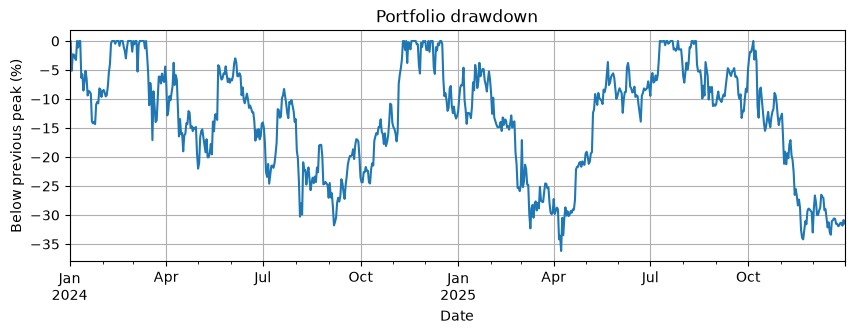

In [6]:
# Highest portfolio value reached up to each date
running_peak = portfolio_value.cummax()

# Percentage below that previous peak
drawdown = portfolio_value / running_peak - 1

trough_date = drawdown.idxmin()
peak_date = portfolio_value.loc[:trough_date].idxmax()

print(f"Maximum drawdown: {drawdown.loc[trough_date]:.2%}")
print(
    f"Peak: {peak_date:%Y-%m-%d}"
    f" | Value: ${portfolio_value.loc[peak_date]:,.2f}"
)
print(
    f"Trough: {trough_date:%Y-%m-%d}"
    f" | Value: ${portfolio_value.loc[trough_date]:,.2f}"
)

drawdown.mul(100).plot(
    figsize=(10, 3),
    title="Portfolio drawdown",
    ylabel="Below previous peak (%)",
    xlabel="Date",
    grid=True
)

In [7]:
# Each asset's share of the portfolio on each date
weights = asset_values.div(portfolio_value, axis="index")

print("Allocation on the final dataset date (%):")
display((weights.iloc[-1] * 100).round(2))

# Hypothetical project limit 
concentration_limit = 0.60

exposure_report = pd.DataFrame({
    "Value (USD)": asset_values.iloc[-1],
    "Portfolio share (%)": weights.iloc[-1] * 100,
    "Above 60% limit": weights.iloc[-1] > concentration_limit
})

display(exposure_report.round(2))

Allocation on the final dataset date (%):


BTC    78.56
ETH    21.44
Name: 2025-12-31 00:00:00, dtype: float64

,Value (USD),Portfolio share (%),Above 60% limit
BTC,13869.11,78.56,True
ETH,3783.96,21.44,False


In [8]:
# Hypothetical shocks, not predictions
shocks = pd.DataFrame({
    "BTC": [-0.10, -0.20, -0.30],
    "ETH": [-0.15, -0.30, -0.40]
}, index=["Scenario 1", "Scenario 2", "Scenario 3"])

latest_values = asset_values.iloc[-1]
latest_total = portfolio_value.iloc[-1]

# Apply each shock to the corresponding asset's value
scenario_pnl = shocks.mul(latest_values, axis="columns").sum(axis=1)

stress_report = pd.DataFrame({
    "BTC change (%)": shocks["BTC"] * 100,
    "ETH change (%)": shocks["ETH"] * 100,
    "Loss (USD)": -scenario_pnl,
    "Portfolio loss (%)": -scenario_pnl / latest_total * 100,
    "Remaining value (USD)": latest_total + scenario_pnl
})

display(stress_report.round(2))

,BTC change (%),ETH change (%),Loss (USD),Portfolio loss (%),Remaining value (USD)
Scenario 1,-10.0,-15.0,1954.51,11.07,15698.57
Scenario 2,-20.0,-30.0,3909.01,22.14,13744.06
Scenario 3,-30.0,-40.0,5674.32,32.14,11978.76


In [9]:
daily_volatility = pd.Series({
    "BTC": returns["BTC"].std(),
    "ETH": returns["ETH"].std(),
    "Portfolio": portfolio_returns.std()
})

print("Daily volatility (%):")
display((daily_volatility * 100).round(2))


Daily volatility (%):


BTC          2.52
ETH          3.68
Portfolio    2.63
dtype: float64

In [10]:
# Replay historical daily returns at the final allocation
final_weights = weights.iloc[-1]
replayed_returns = returns.mul(
    final_weights, axis="columns"
).sum(axis=1)

fifth_percentile = replayed_returns.quantile(0.05)
var_95 = max(0, -fifth_percentile)
var_usd = var_95 * latest_total

print(f"As-of date: {prices.index[-1]:%Y-%m-%d}")
print(f"One-day historical VaR (95%): {var_95:.2%}")
print(f"Equivalent loss threshold: ${var_usd:,.2f}")



As-of date: 2025-12-31
One-day historical VaR (95%): 4.10%
Equivalent loss threshold: $723.27


In [11]:
# Select the worst 5% of replayed historical daily returns
tail_returns = replayed_returns[
    replayed_returns <= fifth_percentile
]

expected_shortfall = -tail_returns.mean()
es_usd = expected_shortfall * latest_total

print(f"Historical tail scenarios: {len(tail_returns)}")
print(f"One-day Expected Shortfall (95%): {expected_shortfall:.2%}")
print(f"Equivalent average tail loss: ${es_usd:,.2f}")

Historical tail scenarios: 37
One-day Expected Shortfall (95%): 5.68%
Equivalent average tail loss: $1,002.25


In [12]:
current_drawdown = -drawdown.iloc[-1]
max_concentration = weights.iloc[-1].max()

dashboard = pd.DataFrame([
    {
        "Indicator": "Largest asset share",
        "Value (%)": max_concentration * 100,
        "Review limit (%)": 60,
        "Status": "REVIEW" if max_concentration > .60 else "Within limit"
    },
    {
        "Indicator": "One-day historical VaR (95%)",
        "Value (%)": var_95 * 100,
        "Review limit (%)": 5,
        "Status": "REVIEW" if var_95 > .05 else "Within limit"
    },
    {
        "Indicator": "Current drawdown",
        "Value (%)": current_drawdown * 100,
        "Review limit (%)": 20,
        "Status": "REVIEW" if current_drawdown > .20 else "Within limit"
    }
])

print(f"Snapshot date: {prices.index[-1]:%Y-%m-%d}")
print(f"Portfolio value: ${latest_total:,.2f}")
print(f"Expected Shortfall (95%): ${es_usd:,.2f}")
display(dashboard.round(2))

Snapshot date: 2025-12-31
Portfolio value: $17,653.07
Expected Shortfall (95%): $1,002.25


,Indicator,Value (%),Review limit (%),Status
0,Largest asset share,78.56,60,REVIEW
1,One-day historical VaR (95%),4.10,5,Within limit
2,Current drawdown,31.45,20,REVIEW


## Risk assessment and recommendation

1. Limits breached: BTC concentration reached 78.56%, exceeding the hypothetical 60% single asset exposure limit. Current drawdown reached 31.45%, exceeding the hypothetical 20% drawdown limit.  

2. Risk interpretation: The 95% one-day historical VaR of 4.10% remained below the hypothetical 5% limit. However, VaR measures the daily loss risk, while drawdown measures the cumulative decline from a prior peak. Compliance with the VaR limit does not offset the concentration and drawdown breaches. 

3. Recommended review: Assess BTC exposure against the company's risk appetite, loss-bearing capacity, and near-term cash obligations before determining whether portfolio adjustments are warranted.

4. Limitations: The analysis uses historical market prices with hypothetical holdings and risk limits. Transaction costs and liquidity constraints are excluded. Historical results do not guarantee future outcomes or establish a maximum possible loss.


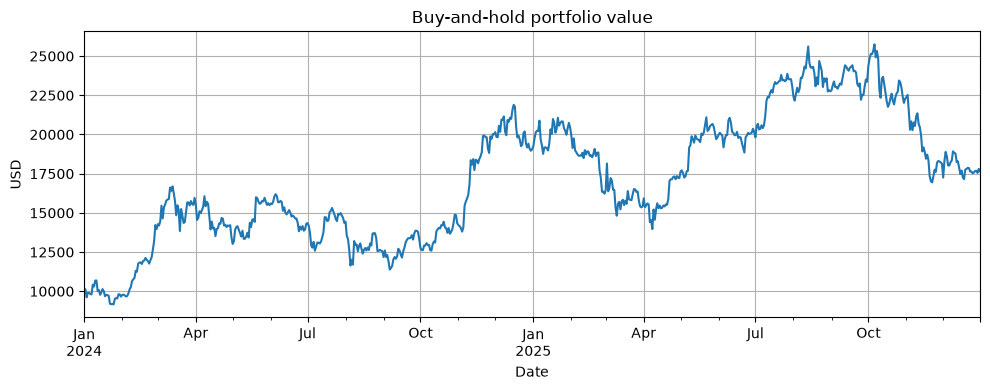

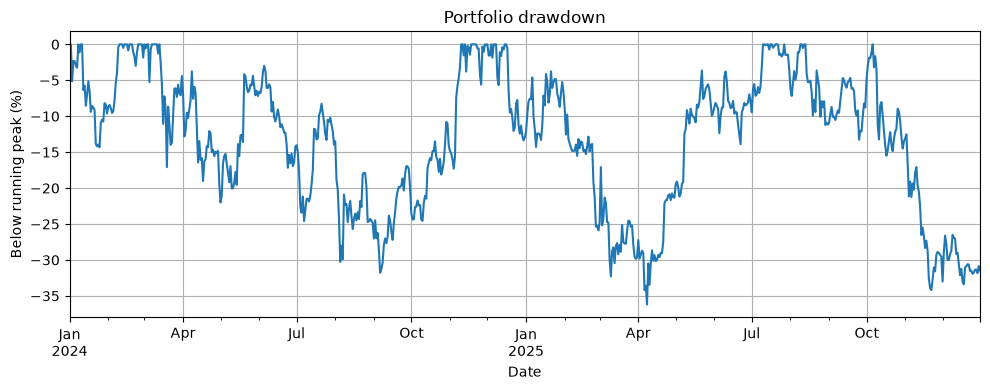

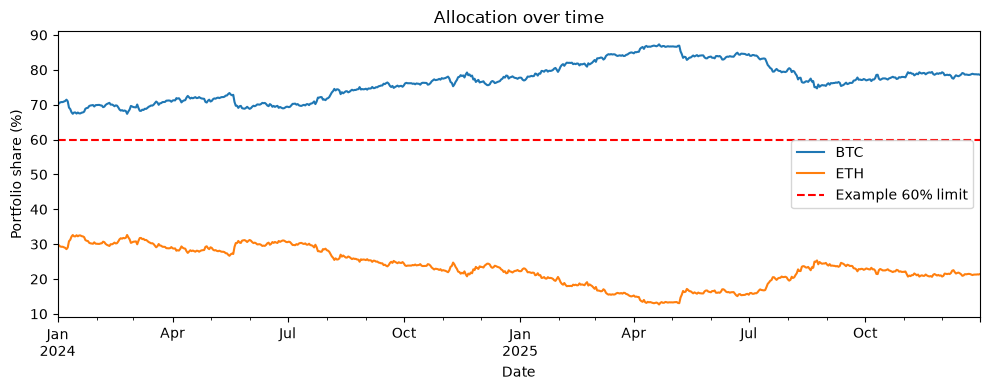

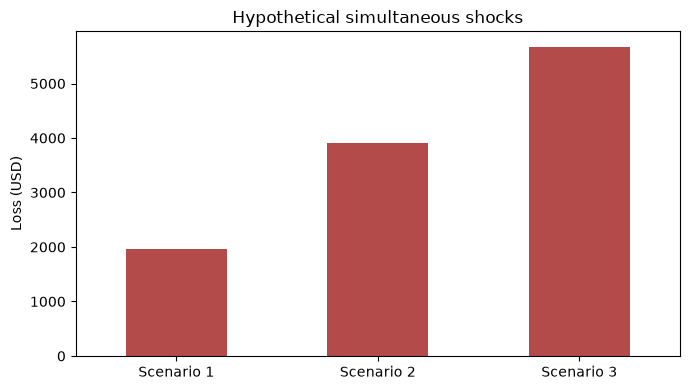

Charts and CSVs saved in outputs/


In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
out = Path('outputs')
out.mkdir(exist_ok=True)
assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert prices.notna().all().all() and (prices > 0).all().all()
expected_dates = pd.date_range(prices.index.min(), prices.index.max(), freq='D')
assert len(expected_dates.difference(prices.index)) == 0, 'Missing daily dates'
prices.to_csv(out / 'prices.csv')
returns.to_csv(out / 'daily_returns.csv')
asset_values.to_csv(out / 'asset_values.csv')
weights.to_csv(out / 'portfolio_weights.csv')
pd.DataFrame({'value_usd': portfolio_value, 'drawdown': drawdown}).to_csv(out / 'portfolio_history.csv')
exposure_report.to_csv(out / 'exposure_report.csv')
stress_report.to_csv(out / 'stress_report.csv')
dashboard.to_csv(out / 'risk_dashboard.csv', index=False)
replayed_returns.to_csv(out / 'replayed_daily_returns.csv', header=['return'])
for name, series, title, ylabel in [
    ('portfolio_value', portfolio_value, 'Buy-and-hold portfolio value', 'USD'),
    ('drawdown', drawdown * 100, 'Portfolio drawdown', 'Below running peak (%)')
]:
    fig, ax = plt.subplots(figsize=(10,4))
    series.plot(ax=ax, title=title, ylabel=ylabel, grid=True)
    fig.tight_layout(); fig.savefig(out / f'{name}.png', dpi=180); plt.show()
fig, ax = plt.subplots(figsize=(10,4))
(weights * 100).plot(ax=ax, ylabel='Portfolio share (%)', title='Allocation over time')
ax.axhline(60, color='red', linestyle='--', label='Example 60% limit')
ax.legend(); fig.tight_layout(); fig.savefig(out / 'allocation_history.png', dpi=180); plt.show()
fig, ax = plt.subplots(figsize=(7,4))
stress_report['Loss (USD)'].plot.bar(ax=ax, color='#b44b4b', rot=0, ylabel='Loss (USD)', title='Hypothetical simultaneous shocks')
fig.tight_layout(); fig.savefig(out / 'stress_losses.png', dpi=180); plt.show()
print('Charts and CSVs saved in outputs/')
